In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.model_selection import train_test_split, KFold ,cross_val_score
from sklearn.base import BaseEstimator,TransformerMixin
import sklearn.metrics as met
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,ExtraTreesClassifier,AdaBoostClassifier,GradientBoostingClassifier
import xgboost

In [5]:
df=pd.read_csv("../Datasets/Student_Addiction.csv")

In [6]:
df.head()

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,1
1,1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,0
2,2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,0
3,3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,NaN,1
4,4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,1


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 691369 entries, 0 to 691368
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       691369 non-null  int64  
 1   age                      662440 non-null  float64
 2   daily_screen_time_hours  595515 non-null  float64
 3   social_media_hours       557374 non-null  float64
 4   gaming_hours             564548 non-null  float64
 5   work_study_hours         639851 non-null  float64
 6   sleep_hours              646889 non-null  float64
 7   notifications_per_day    623785 non-null  float64
 8   app_opens_per_day        610659 non-null  float64
 9   weekend_screen_time      579306 non-null  float64
 10  gender                   662335 non-null  object 
 11  stress_level             636221 non-null  object 
 12  academic_work_impact     647145 non-null  object 
 13  addicted_label           691369 non-null  int64  
dtypes: f

In [8]:
df.isnull().mean()*100

id                          0.000000
age                         4.184307
daily_screen_time_hours    13.864376
social_media_hours         19.381112
gaming_hours               18.343461
work_study_hours            7.451592
sleep_hours                 6.433612
notifications_per_day       9.775388
app_opens_per_day          11.673940
weekend_screen_time        16.208855
gender                      4.199494
stress_level                7.976638
academic_work_impact        6.396584
addicted_label              0.000000
dtype: float64

## Basic model training(dropping null values)

In [8]:
new_df=df.dropna()

In [9]:
new_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 269185 entries, 5 to 691365
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       269185 non-null  int64  
 1   age                      269185 non-null  float64
 2   daily_screen_time_hours  269185 non-null  float64
 3   social_media_hours       269185 non-null  float64
 4   gaming_hours             269185 non-null  float64
 5   work_study_hours         269185 non-null  float64
 6   sleep_hours              269185 non-null  float64
 7   notifications_per_day    269185 non-null  float64
 8   app_opens_per_day        269185 non-null  float64
 9   weekend_screen_time      269185 non-null  float64
 10  gender                   269185 non-null  object 
 11  stress_level             269185 non-null  object 
 12  academic_work_impact     269185 non-null  object 
 13  addicted_label           269185 non-null  int64  
dtypes: float6

In [10]:
new_df.shape

(269185, 14)

In [12]:
ctf=ColumnTransformer([
    ('trf1',OneHotEncoder(drop='first'),['gender','stress_level','academic_work_impact']),
    ('scale',StandardScaler(),['daily_screen_time_hours','social_media_hours','gaming_hours','work_study_hours','sleep_hours','notifications_per_day','app_opens_per_day','weekend_screen_time'])
],remainder='passthrough')

In [13]:
X=new_df.drop(columns=['addicted_label'])
y=new_df['addicted_label']
X=ctf.fit_transform(X)

In [14]:
X.shape

(269185, 15)

In [15]:
X_train1,X_test1,y_train1,y_test1=train_test_split(X,y,test_size=0.25,random_state=42)

In [16]:
model1=LogisticRegression(max_iter=500)

In [18]:
model1.fit(X_train1,y_train1)

C:\Users\yarak\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [19]:
y_pred1=model1.predict(X_test1)

In [20]:
met.accuracy_score(y_test1,y_pred1)

0.8552238584186517

In [21]:
met.roc_auc_score(y_test1,y_pred1)

0.8218943185894404

In [22]:
pd.DataFrame(met.confusion_matrix(y_test1,y_pred1))

,0,1
0,14603,5090
1,4653,42951


**model does not perfrom well so we continue with preprocessing work**

## MODEL BULIDING WITH PIPELINES

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 691369 entries, 0 to 691368
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       691369 non-null  int64  
 1   age                      662440 non-null  float64
 2   daily_screen_time_hours  595515 non-null  float64
 3   social_media_hours       557374 non-null  float64
 4   gaming_hours             564548 non-null  float64
 5   work_study_hours         639851 non-null  float64
 6   sleep_hours              646889 non-null  float64
 7   notifications_per_day    623785 non-null  float64
 8   app_opens_per_day        610659 non-null  float64
 9   weekend_screen_time      579306 non-null  float64
 10  gender                   662335 non-null  object 
 11  stress_level             636221 non-null  object 
 12  academic_work_impact     647145 non-null  object 
 13  addicted_label           691369 non-null  int64  
dtypes: f

In [10]:
df.describe()

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,addicted_label
count,691369.000000,662440.000000,595515.000000,557374.000000,564548.000000,639851.000000,646889.000000,623785.000000,610659.000000,579306.000000,691369.000000
mean,345684.000000,26.615408,7.640865,2.471038,1.459265,2.366971,6.804334,145.894900,102.636781,9.479866,0.709424
std,199581.183467,5.153162,2.721446,1.316137,0.934552,1.258797,1.234512,65.917556,48.093970,2.856006,0.454028
min,0.000000,18.000000,0.500000,0.000000,0.000000,0.000000,4.500000,20.000000,15.000000,0.510000,0.000000
25%,172842.000000,22.000000,5.480000,1.450000,0.700000,1.360000,5.780000,93.000000,64.000000,7.280000,0.000000
50%,345684.000000,27.000000,7.770000,2.310000,1.330000,2.200000,6.800000,150.000000,104.000000,9.580000,1.000000
75%,518526.000000,31.000000,9.840000,3.370000,2.090000,3.200000,7.870000,204.000000,145.000000,11.750000,1.000000
max,691368.000000,35.000000,15.000000,8.000000,4.000000,6.000000,9.000000,250.000000,180.000000,17.560000,1.000000


In [11]:
X_train,X_test,y_train,y_test=train_test_split(df.drop(columns=['addicted_label','id']),df['addicted_label'],test_size=0.2,random_state=42)

In [12]:
X_train.isnull().mean()*100

age                         4.181018
daily_screen_time_hours    13.886041
social_media_hours         19.388713
gaming_hours               18.355436
work_study_hours            7.455320
sleep_hours                 6.429818
notifications_per_day       9.763603
app_opens_per_day          11.691662
weekend_screen_time        16.208608
gender                      4.211392
stress_level                8.001157
academic_work_impact        6.429637
dtype: float64

#### Sampling the data for faster training

In [13]:
sample_Xtrain=X_train.sample(int(X_train.shape[0]*0.25))

In [14]:
sample_ytrain=y_train.loc[sample_Xtrain.index]

In [15]:
sample_Xtrain.head(3)

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact
157265,23.0,8.08,2.86,1.15,3.03,5.77,93.0,85.0,9.76,NaN,High,Yes
71156,NaN,7.21,2.54,2.37,1.54,8.73,153.0,179.0,11.13,Other,High,Yes
289347,31.0,6.62,0.71,3.63,1.27,NaN,129.0,105.0,8.45,Other,NaN,No


In [16]:
sample_Xtrain.shape

(138273, 12)

In [17]:
sample_ytrain.head(3)

157265    1
71156     1
289347    1
Name: addicted_label, dtype: int64

In [18]:
X_train2,X_test2,y_train2,y_test2=train_test_split(sample_Xtrain,sample_ytrain,test_size=0.2,random_state=42)

### PREPROCESSING THE DATA


- for age and categorical columns we will use random imputation
- for remaing columns use mean/median
- we have to onehot encode the categorical columns
- scale the numerical columns

##### Creating random imputer class

In [19]:
class RandomImputer(BaseEstimator,TransformerMixin):
    def __init__(self,random_state=42):
        self.random_state=random_state
    def fit(self,X_train,y_train):
        X=pd.DataFrame(X_train).copy()
        self.columns_=X.columns
        self.values_={}
        for col in self.columns_:
            self.values_[col]=X[col].dropna().unique()
        return self
    def transform(self,X_train,y_train=None):
        X=pd.DataFrame(X_train).copy()
        rng=np.random.default_rng(self.random_state)
        for col in self.columns_:
            mask=X[col].isna()
            n_missing=mask.sum()
            if n_missing>0:
                random_values=rng.choice(self.values_[col],size=n_missing,replace=True)
                X.loc[mask,col]=random_values
        return X

#### Preprocessing the data

In [20]:
df.columns

Index(['id', 'age', 'daily_screen_time_hours', 'social_media_hours',
       'gaming_hours', 'work_study_hours', 'sleep_hours',
       'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time',
       'gender', 'stress_level', 'academic_work_impact', 'addicted_label'],
      dtype='object')

In [21]:
pipe1=Pipeline([
    ('random_impute',RandomImputer()),
    ('ohe',OneHotEncoder(drop='first',sparse_output=False))
])

pipe2=Pipeline(steps=[
    ('mean_impute',SimpleImputer(strategy='mean')),
    ('scaler',StandardScaler())
])
pipe3=Pipeline([
    ('random_impute',RandomImputer()),
    ('scaler',StandardScaler())    
])

trf=ColumnTransformer(transformers=[
    ('pipe1',pipe1,['gender','stress_level','academic_work_impact']),
    ('pipe2',pipe2,['daily_screen_time_hours', 'social_media_hours','gaming_hours', 'work_study_hours', 'sleep_hours','notifications_per_day', 'app_opens_per_day', 'weekend_screen_time',]),
    ('pipe3',pipe3,['age'])
],remainder='passthrough')

In [22]:
final_pipe=Pipeline([
    ('preprocess',trf),
    ('model',DecisionTreeClassifier())
])

In [22]:
kfold=KFold(shuffle=True,random_state=42)
score=cross_val_score(final_pipe,X_train2,y_train2,cv=kfold,scoring='roc_auc')

In [23]:
score.mean()

np.float64(0.7752527067730665)

In [24]:
final_pipe.fit(X_train2,y_train2)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('pipe1', ...), ('pipe2', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different t

In [25]:
y_pred2=final_pipe.predict(X_test2)

In [26]:
met.roc_auc_score(y_test2,y_pred2)

0.77321847097568

In [23]:
X_train2_trf=trf.fit_transform(X_train2,y_train2)
X_test2_trf=trf.transform(X_test2)

In [24]:
X_test2_trf.shape

(27655, 14)

In [30]:
def training(model_name,model):
    output=[]
    output.append(model_name)
    kfold=KFold(n_splits=5,shuffle=True,random_state=42)
    scores=cross_val_score(model,X_train2_trf,y_train2,cv=kfold)
    output.append(scores.mean())
    model.fit(X_train2_trf,y_train2)
    y_pred=model.predict(X_test2_trf)
    roc_score=met.roc_auc_score(y_test2,y_pred)
    output.append(roc_score)
    return output

In [81]:
models={
    'Logistic_regression':LogisticRegression(),
    'svc':SVC(),
    'Decsion trees':DecisionTreeClassifier(),
    'Random forest':RandomForestClassifier(),
    'extra trees':ExtraTreesClassifier(),
    'Adaboost':AdaBoostClassifier(),
    'Gradient boosting':GradientBoostingClassifier(),
    'XGBOOST':xgboost.XGBClassifier()
}

In [85]:
model_output=[]
for model_name,model in models.items():
    model_output.append(training(model_name,model))

In [86]:
df=pd.DataFrame(model_output,columns=['model','r2','roc_score'])

In [91]:
df

,model,r2,roc_score
0,Logistic_regression,0.839398,0.779402
1,svc,0.850427,0.804817
2,Decsion trees,0.813588,0.773222
3,Random forest,0.862315,0.826611
4,extra trees,0.854450,0.812386
5,Adaboost,0.834426,0.811794
6,Gradient boosting,0.862044,0.830522
7,XGBOOST,0.875876,0.843403


In [26]:
top_models={
    'Random forest':RandomForestClassifier(),
    'extra trees':ExtraTreesClassifier(),
    'Gradient boosting':GradientBoostingClassifier(),
    'XGBOOST':xgboost.XGBClassifier()
}

In [31]:
model_output2=[]
for model_name,model in top_models.items():
    model_output2.append(training(model_name,model))

In [32]:
df2=pd.DataFrame(model_output2,columns=['model','r2','roc_score'])
df2

,model,r2,roc_score
0,Random forest,0.864425,0.830810
1,extra trees,0.857103,0.822745
2,Gradient boosting,0.862717,0.837425
3,XGBOOST,0.890253,0.864226


### MLP ARCHITECTURE--from deep learning

In [2]:
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [26]:
X_train2_trf.shape

(110618, 14)

In [74]:
model=Sequential()

In [75]:
model.add(Dense(14,activation='relu',input_shape=(14,)))
model.add(Dense(14,activation='sigmoid'))
model.add(Dense(14,activation='sigmoid'))
model.add(Dense(14,activation='sigmoid'))
model.add(Dense(1,activation='sigmoid'))

In [76]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_35 (Dense)                     │ (None, 14)                  │             210 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_36 (Dense)                     │ (None, 14)                  │             210 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_37 (Dense)                     │ (None, 14)                  │             210 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_38 (Dense)                     │ (None, 14)                  │             210 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_39 (Dense)                     │ (None, 1)                   │              15 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 855 (3.34 KB)

 Trainable params: 855 (3.34 KB)

 Non-trainable params: 0 (0.00 B)

In [77]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [79]:
history=model.fit(X_train2_trf,y_train2,batch_size=64,validation_split=0.2,epochs=25)

Epoch 1/25
1383/1383 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8466 - loss: 0.3155 - val_accuracy: 0.8429 - val_loss: 0.3142
Epoch 2/25
1383/1383 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8478 - loss: 0.3112 - val_accuracy: 0.8426 - val_loss: 0.3168
Epoch 3/25
1383/1383 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8491 - loss: 0.3091 - val_accuracy: 0.8456 - val_loss: 0.3114
Epoch 4/25
1383/1383 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8498 - loss: 0.3074 - val_accuracy: 0.8466 - val_loss: 0.3120
Epoch 5/25
1383/1383 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8518 - loss: 0.3057 - val_accuracy: 0.8483 - val_loss: 0.3076
Epoch 6/25
1383/1383 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8528 - loss: 0.3050 - val_accuracy: 0.8487 - val_loss: 0.3067
Epoch 7/25
1383/1383 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8533 - loss: 0.3039 - val_accuracy: 0.8488 - val_loss: 0.3071
Epoch 8/25
1383/1383 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.8534 - loss: 0.3032 -

In [83]:
y_prob=model.predict(X_test2_trf)

865/865 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


In [84]:
y_pred2=np.where(y_prob>0.5,1,0)
roc_score=met.roc_auc_score(y_test2,y_pred2)
print(roc_score)

0.8100430154764436


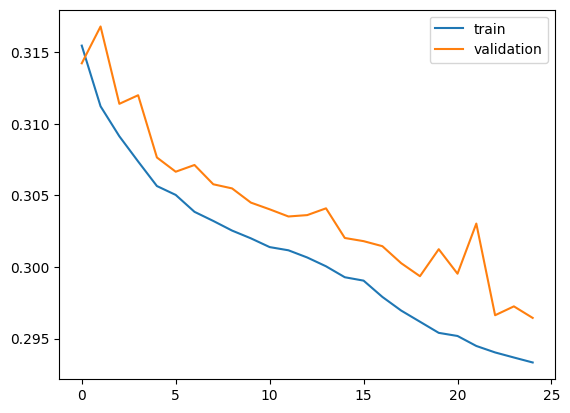

In [85]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.legend(["train", "validation"])
plt.show()

**SUMMARY**
- xgboost model works better than all the other models so use XGBOOST and tune its parameters